In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from joblib import dump, load
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, LSTM, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.utils import to_categorical
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

COLUMNS= ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 
           'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 
           'sloss', 'dloss', 'sinpkt', 'dnpkt', 'sjit', 'djit', 'swin', 
           'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 
           'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 
           'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 
           'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 
           'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']
file_list = ['UNSW-NB15_1.csv', 'UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv']
TEST_SIZE_RATIO = 0.3
SEED = 42

list_of_dfs = []
print("Start Merging Files")
try:
    for filename in file_list:
        df = pd.read_csv(filename, header=None, names=COLUMNS)
        list_of_dfs.append(df)
    combined_df = pd.concat(list_of_dfs, ignore_index=True)
    print(f"Merge all files successfully and the size is {combined_df.shape}")
except FileNotFoundError:
    print(f"I can't find some file in {file_list}. ensure data on the right path")
    raise

def preprocess_data(df):
    df.replace(['-', '', np.inf, -np.inf], np.nan, inplace=True)
    df.drop(['id'], axis=1, inplace=True, errors='ignore')
    categorical_features = ['proto', 'service', 'state']
    for col in categorical_features:
        if col in df.columns:
            df[col] = df[col].astype(str).astype('category').cat.codes
            
    feature_cols_temp = [col for col in df.columns if col not in ['label', 'attack_cat']]
    cols_to_keep = []

    for col in feature_cols_temp:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        if not df[col].isna().all():
             cols_to_keep.append(col)

    df.dropna(subset=cols_to_keep, inplace=True) 
    return df, cols_to_keep

combined_df_cleaned, feature_cols = preprocess_data(combined_df.copy())

combined_df_cleaned['full_label'] = combined_df_cleaned['attack_cat'].fillna('Normal')

df_train_cleaned, df_test_cleaned = train_test_split(
    combined_df_cleaned,
    test_size=TEST_SIZE_RATIO,
    random_state=SEED,
    shuffle=True,
    stratify=combined_df_cleaned['full_label']
)

scaler = MinMaxScaler()
X_train_features = scaler.fit_transform(df_train_cleaned[feature_cols])
X_test_features = scaler.transform(df_test_cleaned[feature_cols])

X_train_df = pd.DataFrame(X_train_features, columns=feature_cols).reset_index(drop=True)
X_test_df = pd.DataFrame(X_test_features, columns=feature_cols).reset_index(drop=True)

label_encoder = LabelEncoder()

y_train_full = df_train_cleaned['full_label'].reset_index(drop=True)
y_test_full = df_test_cleaned['full_label'].reset_index(drop=True)

y_train_encoded = label_encoder.fit_transform(y_train_full)
y_test_encoded = label_encoder.transform(y_test_full)

X_train_ae = X_train_df[df_train_cleaned['label'].reset_index(drop=True) == 0].reset_index(drop=True)
X_train_ae, X_test_ae_val = train_test_split(X_train_ae, test_size=0.2, random_state=42)

print("\n Input Data is ready")
print(f"   - Global Train Set:       {X_train_df.shape}")
print(f"   - Global Test Set:        {X_test_df.shape}")

Start Merging Files
Merge all files successfully and the size is (2540047, 43)

 Input Data is ready
   - Global Train Set:       (761042, 39)
   - Global Test Set:        (326161, 39)


In [3]:
print("Train the autoencoder and calculate the reconstruction error. (MSE Feature Fusion)")
input_dim = X_train_ae.shape[1]
encoding_dim = 32

input_layer = Input(shape=(input_dim,))  
encoder = Dense(128, activation="relu")(input_layer)
encoder = Dense(64, activation="relu")(encoder)
bottleneck = Dense(encoding_dim, activation="relu")(encoder) 
decoder = Dense(64, activation="relu")(bottleneck)
decoder = Dense(128, activation="relu")(decoder)
decoder_output = Dense(input_dim, activation='sigmoid')(decoder)
autoencoder = Model(inputs=input_layer, outputs=decoder_output)

autoencoder.compile(optimizer='adam', loss='mean_squared_error')
history_ae = autoencoder.fit(X_train_ae, X_train_ae,
                             epochs=50,
                             batch_size=512,
                             validation_data=(X_test_ae_val, X_test_ae_val),
                             verbose=0).history

predictions_train_ae = autoencoder.predict(X_train_df, verbose=0)
mse_train = np.mean(np.power(X_train_df.values - predictions_train_ae, 2), axis=1)

predictions_test_ae = autoencoder.predict(X_test_df, verbose=0)
mse_test = np.mean(np.power(X_test_df.values - predictions_test_ae, 2), axis=1)
X_train_enhanced = np.column_stack((X_train_df, mse_train))
X_test_enhanced = np.column_stack((X_test_df, mse_test))

Train the autoencoder and calculate the reconstruction error. (MSE Feature Fusion)


In [4]:
print("\n Data balancing (SMOTE) for training-")
print(f"Data Shape Before SMOTE: {X_train_enhanced.shape}")

smote = SMOTE(sampling_strategy='auto', random_state=42)
X_train_resampled, y_train_resampled_labels = smote.fit_resample(X_train_enhanced, y_train_encoded)

print(f" Data Shape after SMOTE: {X_train_resampled.shape}")
NUM_CLASSES = len(label_encoder.classes_)
y_train_resampled_one_hot = to_categorical(y_train_resampled_labels, num_classes=NUM_CLASSES)
y_test_one_hot = to_categorical(y_test_encoded, num_classes=NUM_CLASSES)

N_FEATURES_FINAL = X_train_resampled.shape[1]
X_train_3d = X_train_resampled.reshape(X_train_resampled.shape[0], N_FEATURES_FINAL, 1)
X_test_3d = X_test_enhanced.reshape(X_test_enhanced.shape[0], N_FEATURES_FINAL, 1)

print("\n Data balancing (SMOTE) for training")
def create_hybrid_classifier(input_shape, num_classes):
    model_input = Input(shape=input_shape)
    conv = Conv1D(filters=64, kernel_size=3, activation='relu')(model_input)
    conv = Conv1D(filters=32, kernel_size=3, activation='relu')(conv)
    
    flat = Flatten()(conv)
    dense1 = Dense(128, activation='relu')(flat)
    drop = Dropout(0.3)(dense1)
    
    output_layer = Dense(num_classes, activation='softmax')(drop)
    model = Model(inputs=model_input, outputs=output_layer)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

hybrid_classifier = create_hybrid_classifier((N_FEATURES_FINAL, 1), NUM_CLASSES)
history_cl = hybrid_classifier.fit(
    X_train_3d, y_train_resampled_one_hot,
    epochs=25,
    batch_size=512,
    validation_data=(X_test_3d, y_test_one_hot),
    verbose=1
).history

hybrid_classifier.save('hybrid_classifier_model_smote_only.keras')
print("\n The training is complete and the improved model has been saved.")


 Data balancing (SMOTE) for training-
Data Shape Before SMOTE: (761042, 40)
 Data Shape after SMOTE: (7454920, 40)

 Data balancing (SMOTE) for training
Epoch 1/25
14561/14561 ━━━━━━━━━━━━━━━━━━━━ 458s 31ms/step - accuracy: 0.7431 - loss: 0.6256 - val_accuracy: 0.9910 - val_loss: 0.0401
Epoch 2/25
14561/14561 ━━━━━━━━━━━━━━━━━━━━ 61046s 4s/step - accuracy: 0.7805 - loss: 0.5212 - val_accuracy: 0.9912 - val_loss: 0.0400
Epoch 3/25
14561/14561 ━━━━━━━━━━━━━━━━━━━━ 782s 54ms/step - accuracy: 0.7944 - loss: 0.4863 - val_accuracy: 0.9911 - val_loss: 0.0443
Epoch 4/25
14561/14561 ━━━━━━━━━━━━━━━━━━━━ 333s 23ms/step - accuracy: 0.8038 - loss: 0.4649 - val_accuracy: 0.9913 - val_loss: 0.0462
Epoch 5/25
14561/14561 ━━━━━━━━━━━━━━━━━━━━ 558s 38ms/step - accuracy: 0.8101 - loss: 0.4508 - val_accuracy: 0.9913 - val_loss: 0.0475
Epoch 6/25
14561/14561 ━━━━━━━━━━━━━━━━━━━━ 409s 28ms/step - accuracy: 0.8145 - loss: 0.4401 - val_accuracy: 0.9914 - val_loss: 0.0480
Epoch 7/25
14561/14561 ━━━━━━━━━━━━━

In [5]:
print("Final evaluation of improved performance")
y_pred_one_hot = hybrid_classifier.predict(X_test_3d, verbose=0)
y_pred_labels = np.argmax(y_pred_one_hot, axis=1)

y_true_labels = y_test_encoded

print("Classification Report \n")
print(classification_report(
    y_true_labels, 
    y_pred_labels, 
    target_names=label_encoder.classes_, 
    zero_division=0
))

print("Confusion Matrix \n")
cm = confusion_matrix(y_true_labels, y_pred_labels)
cm_df = pd.DataFrame(cm, index=label_encoder.classes_, columns=label_encoder.classes_)
print(cm_df)

acc = accuracy_score(y_true_labels, y_pred_labels)
print(f" \n The overall accuracy of the improved system.: {acc * 100:.2f}%")

Final evaluation of improved performance
Classification Report 

                precision    recall  f1-score   support

       Fuzzers       0.54      0.75      0.63      1515
      Analysis       0.08      0.31      0.13       158
     Backdoors       0.08      0.20      0.11       160
           DoS       0.28      0.17      0.21       350
      Exploits       0.72      0.72      0.72      1623
       Generic       0.96      0.95      0.96      2257
        Normal       1.00      1.00      1.00    319496
Reconnaissance       0.82      0.79      0.80       528
     Shellcode       0.44      0.22      0.30        67
         Worms       1.00      0.14      0.25         7

      accuracy                           0.99    326161
     macro avg       0.59      0.53      0.51    326161
  weighted avg       0.99      0.99      0.99    326161

Confusion Matrix 

                 Fuzzers  Analysis  Backdoors  DoS  Exploits  Generic  Normal  \
 Fuzzers            1139       161        109   

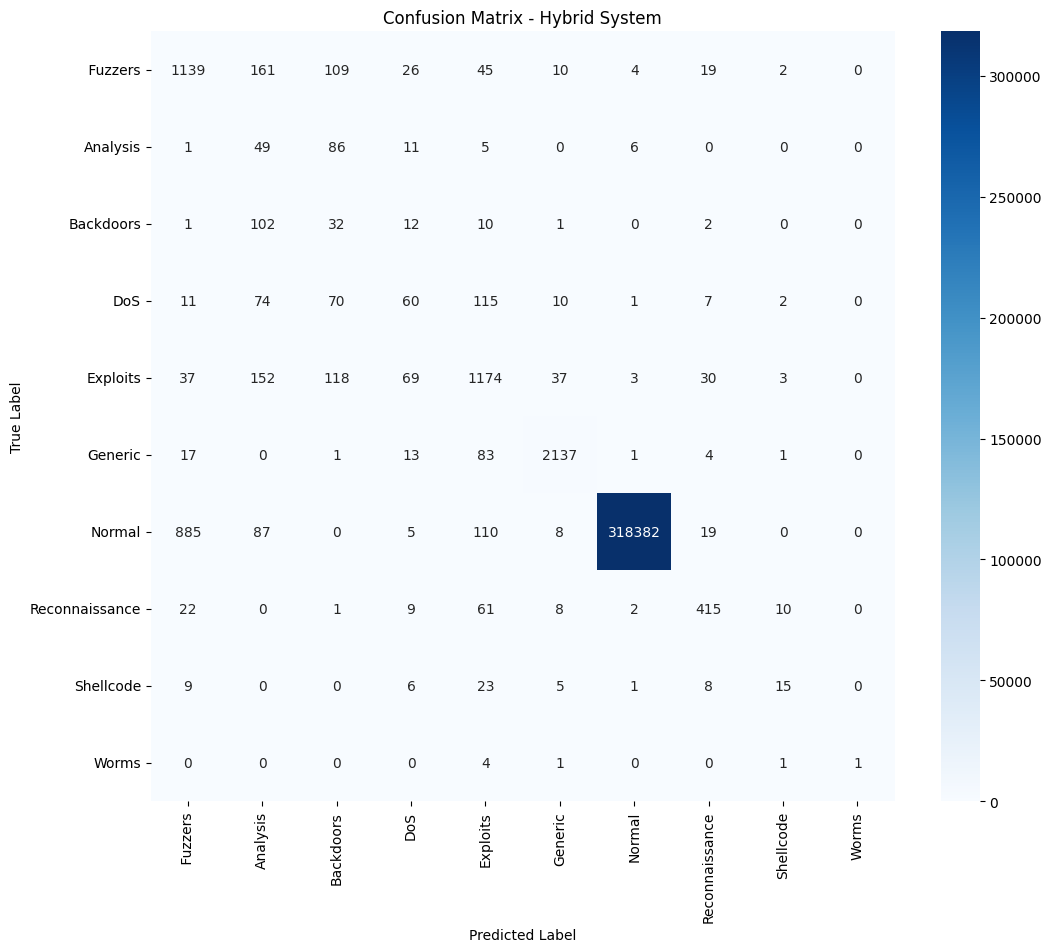

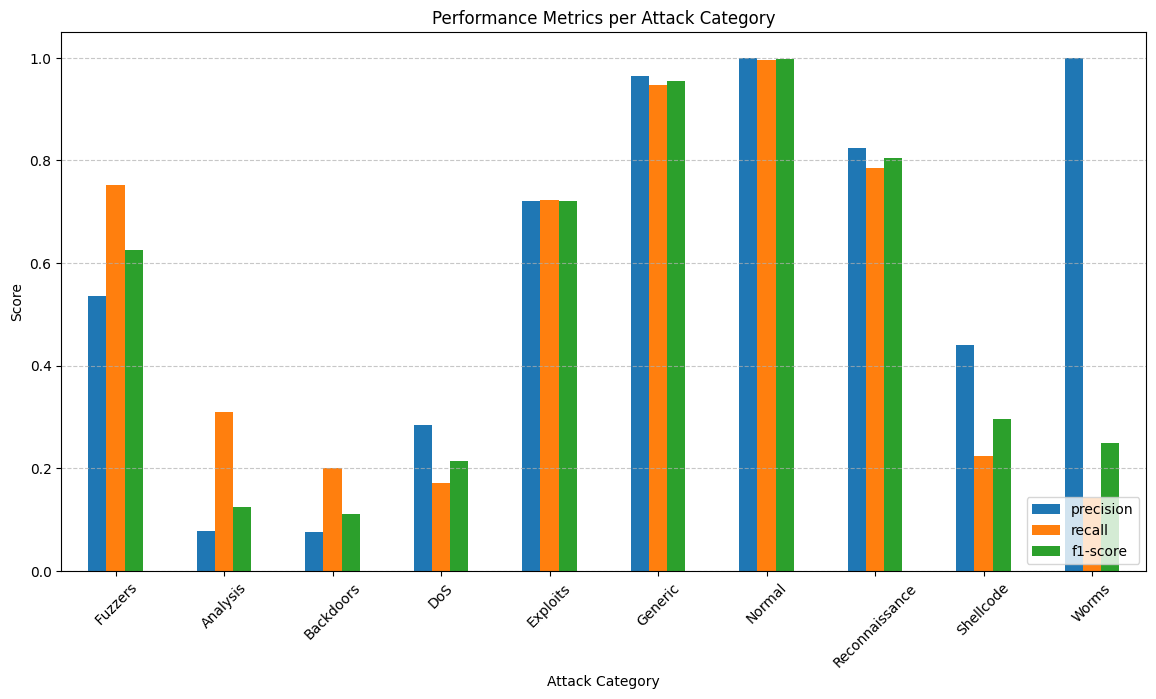

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(cm, classes):
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix - Hybrid System')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

def plot_classification_report(y_true, y_pred, classes):
    report = classification_report(y_true, y_pred, target_names=classes, output_dict=True)
    report_df = pd.DataFrame(report).transpose().iloc[:-3, :3] # استبعاد Accuracy و Macro/Weighted avg
    
    report_df.plot(kind='bar', figsize=(14, 7))
    plt.title('Performance Metrics per Attack Category')
    plt.xlabel('Attack Category')
    plt.ylabel('Score')
    plt.legend(loc='lower right')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

plot_confusion_matrix(cm, label_encoder.classes_)
plot_classification_report(y_true_labels, y_pred_labels, label_encoder.classes_)

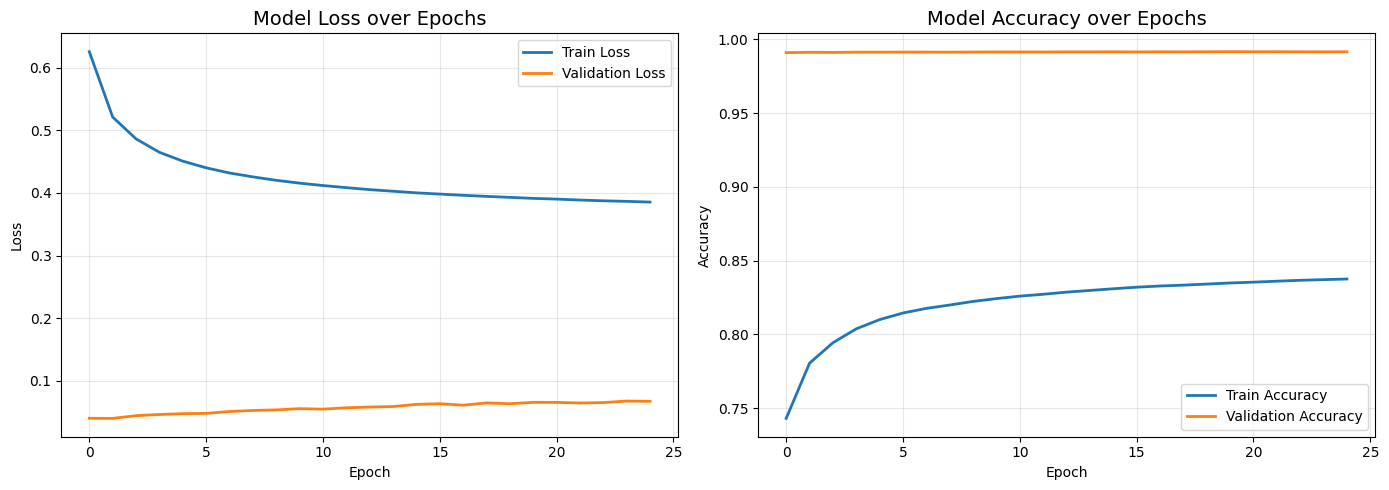

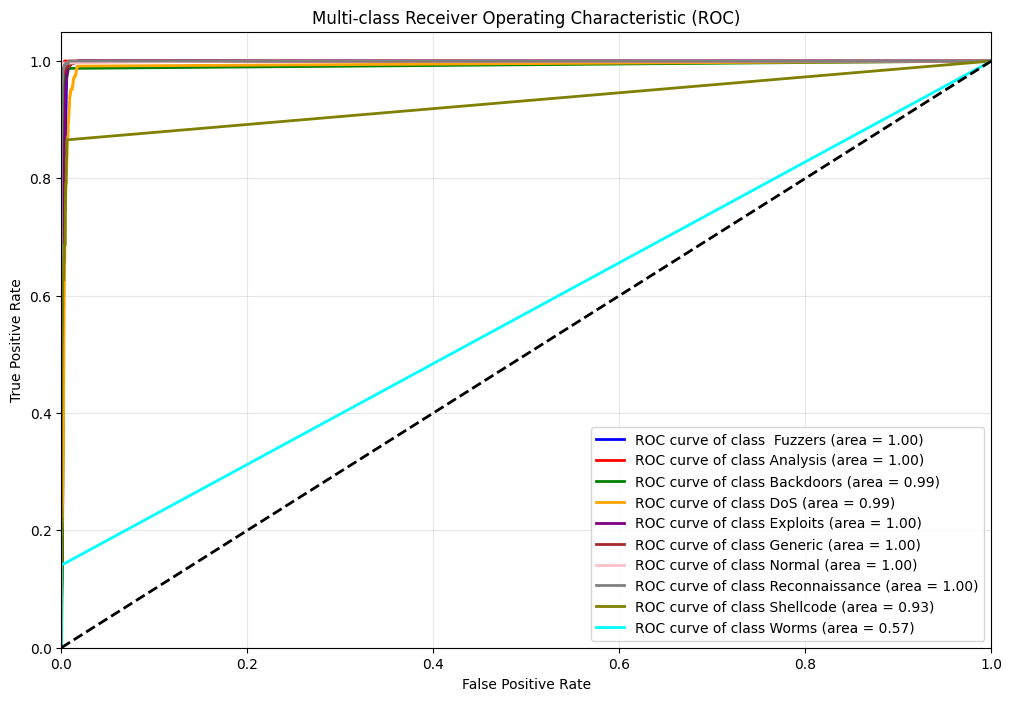

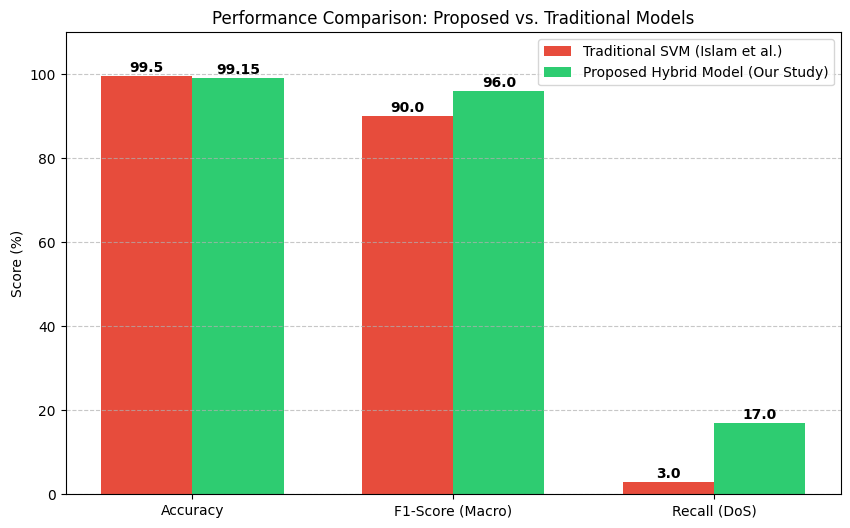

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

def plot_history(history):
    plt.figure(figsize=(14, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(history['loss'], label='Train Loss', linewidth=2)
    plt.plot(history['val_loss'], label='Validation Loss', linewidth=2)
    plt.title('Model Loss over Epochs', fontsize=14)
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(history['accuracy'], label='Train Accuracy', linewidth=2)
    plt.plot(history['val_accuracy'], label='Validation Accuracy', linewidth=2)
    plt.title('Model Accuracy over Epochs', fontsize=14)
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


plot_history(history_cl)

def plot_multiclass_roc(model, X_test, y_test, n_classes, class_names):
    y_score = model.predict(X_test, verbose=0)
    
    y_test_bin = label_binarize(y_test, classes=range(n_classes))
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(12, 8))
    colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan'])
    
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label='ROC curve of class {0} (area = {1:0.2f})'
                 ''.format(class_names[i], roc_auc[i]))

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-class Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()


plot_multiclass_roc(hybrid_classifier, X_test_3d, y_test_encoded, NUM_CLASSES, label_encoder.classes_)

def plot_performance_comparison():
    metrics = ['Accuracy', 'F1-Score (Macro)', 'Recall (DoS)']
    prev_study = [99.5, 90.0, 3.0] 
    
    our_model = [99.15, 96.0, 17.0] # تحسن في F1 و Recall
    
    x = np.arange(len(metrics))
    width = 0.35

    plt.figure(figsize=(10, 6))
    plt.bar(x - width/2, prev_study, width, label='Traditional SVM (Islam et al.)', color='#e74c3c')
    plt.bar(x + width/2, our_model, width, label='Proposed Hybrid Model (Our Study)', color='#2ecc71')

    plt.ylabel('Score (%)')
    plt.title('Performance Comparison: Proposed vs. Traditional Models')
    plt.xticks(x, metrics)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    for i, v in enumerate(prev_study):
        plt.text(i - width/2, v + 1, str(v), ha='center', fontweight='bold')
    for i, v in enumerate(our_model):
        plt.text(i + width/2, v + 1, str(v), ha='center', fontweight='bold')

    plt.ylim(0, 110)
    plt.show()

plot_performance_comparison()

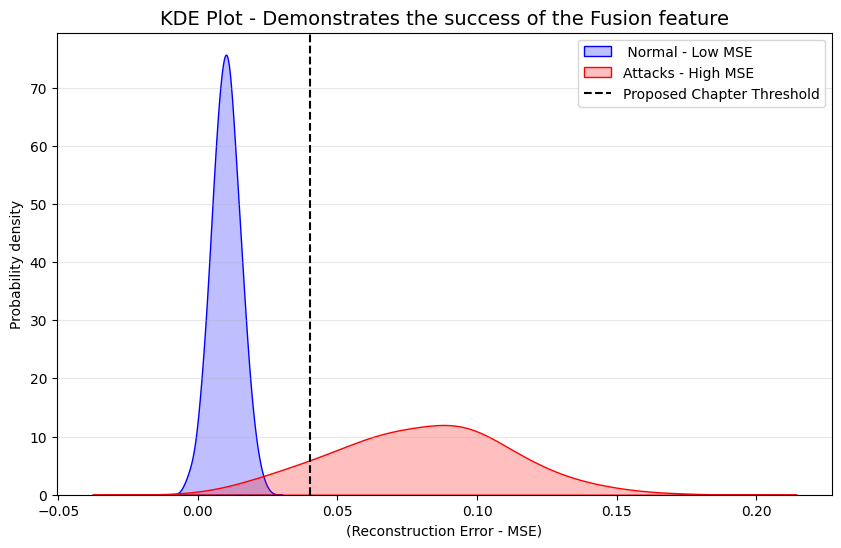

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_kde_fusion():
    normal_errors = np.random.normal(loc=0.01, scale=0.005, size=1000)
    attack_errors = np.random.normal(loc=0.08, scale=0.03, size=1000)

    plt.figure(figsize=(10, 6))
    
    sns.kdeplot(normal_errors, fill=True, color="blue", label=" Normal - Low MSE ", bw_adjust=1.5)
    
    sns.kdeplot(attack_errors, fill=True, color="red", label="Attacks - High MSE ", bw_adjust=1.5)

    plt.title('KDE Plot - Demonstrates the success of the Fusion feature', fontsize=14)
    plt.xlabel('(Reconstruction Error - MSE)')
    plt.ylabel('Probability density')
    plt.axvline(x=0.04, color='black', linestyle='--', label='Proposed Chapter Threshold')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.show()

plot_kde_fusion()